# 資料預處理 Data Preprocessing

資料集:ZINC-250k

是分子生成模型（Molecular Generative Models）的標準基準測試（Benchmark）資料集

## 安裝必要套件
1. 化學資訊學的開源工具包RDKit
2. 加速pandas進行平行化運算的swifter工具包

In [ ]:
!pip install rdkit swifter

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 13.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.1/37.1 MB 34.1 MB/s eta 0:00:00
  Created wheel for swifter: filename=swifter-1.4.0-py3-none-any.whl size=16505 sha256=89bc788f8063c27ef892a9cb0bb673ec5ecf01e16f68002641202fe28fac7d30
  Stored in directory: /root/.cache/pip/wheels/d9/31/ff/ff51141a088571a9f672449e5aad5ea8bb35ca5d95ba135f30
Successfully built swifter


## 匯入必要的python模組
1. numpy 基礎科學計算庫，提供高速多維陣列計算
2. pandas 數據化表格工具
3. switter 運算加速器，可自動評估使用向量化或是平行運算來加速處理工作表
4. tqdm 進度條工具，執行長時間迴圈可以看到即時的處理進度
5. matplotlib 基礎繪圖庫，用於製作折線圖、直方圖等基本圖表
6. seaborn 基於matplotlib的延伸繪圖庫，提供更美觀的統計圖表
7. IPython.display 用於在Jupyter/Colab直接顯示媒體內容
8. google.colab 用於快速與使用者的google雲端硬碟掛載連接的工具
9. shutil 跨平台複製資料的python套件

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import swifter
import shutil
import os
from google.colab import drive
from tqdm import tqdm
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import rdmolops
from rdkit.Chem import Draw
from rdkit.Chem import rdDepictor
from rdkit.Chem import Descriptors
from rdkit.Chem.Scaffolds import MurckoScaffold

In [ ]:
# 自定義新的分子骨架拆解邏輯
## RDkit內建的MurckoScaffold主要設計給含環結構
## 直鏈分子僅回傳一個空字串無法保留骨架的特性
## 因此我們針對直鏈分子定義為最長鏈提取裁切掉支鏈
def get_unified_scaffold(mol):
    # 1. 嘗試提取標準Murcko骨架
    scaf = MurckoScaffold.GetScaffoldForMol(mol)

    # 2. 如果沒有環則提取主鏈作為骨架
    if scaf.GetNumAtoms() == 0:
        # 建立分子樹
        dist_mat = rdmolops.GetDistanceMatrix(mol)
        # 找尋最長路徑的起點與終點
        start, end = np.unravel_index(dist_mat.argmax(), dist_mat.shape)
        path = rdmolops.GetShortestPath(mol, int(start), int(end))
        # 建立主鏈分子
        edit_mol = Chem.EditableMol(mol)
        for idx in sorted([a.GetIdx() for a in mol.GetAtoms()], reverse=True):
            if idx not in path:
                edit_mol.RemoveAtom(idx)
        scaf = edit_mol.GetMol()

    # 3. 統一執行全碳化
    generic_scaf = MurckoScaffold.MakeScaffoldGeneric(scaf)
    return scaf, generic_scaf



def full_pipline(smiles):
    try:
        mol = Chem.MolFromSmiles(smiles)
        if not mol:
            return None

        # 規範化與加氫
        canon_smiles = Chem.MolToSmiles(mol, isomericSmiles=True)
        mol_with_Hs = Chem.AddHs(mol)

        # 提取標準骨架以及通用化骨架
        scaf_mol, generic_mol = get_unified_scaffold(mol)

        # 計算特性
        ## 規範化可降低模型學習成本加速收斂
        ## 分子量MolWt對於是否有加氫會產生不同結果
        ## 其餘計算則不影響
        data = {
            'SMILES': canon_smiles,
            'Standard_Scaffold': Chem.MolToSmiles(scaf_mol),
            'Generic_Scaffold': Chem.MolToSmiles(generic_mol),
            'MW': Descriptors.MolWt(mol_with_Hs),
            'LogP': Descriptors.MolLogP(mol),
            'HBD': Descriptors.NumHDonors(mol),
            'HBA': Descriptors.NumHAcceptors(mol),
            'ROB': Descriptors.NumRotatableBonds(mol),
            'TPSA': Descriptors.TPSA(mol)
        }
        return data
    except Exception as e:
        print(f"Fail: {smiles} - {e}")
        return None




In [ ]:
drive.mount('/content/drive')
input_file_path = '/content/drive/MyDrive/MD_and_CADD/smiles_all.txt'
local_file_path = '/content/smiles_all.txt'
shutil.copy(input_file_path, local_file_path)

# 1. 建立原始的SMILES的DataFrame
with open(input_file_path, 'r') as f:
    all_smiles = [line.strip() for line in f]

df = pd.DataFrame(all_smiles, columns=['Raw_SMILES'])
print(f"原始分子總數: {len(df)}")

Mounted at /content/drive
原始分子總數: 249456


In [ ]:
# 2. 使用apply快速建立所有欄位

tqdm.pandas(desc="正在處理分子骨架與特徵")

# result_type='expand' 會自動將回傳的 dictionary 轉成新的 Columns
# tqdm.pandas()可以產生進度條
## tqdm.pandas(desc="正在處理分子骨架與特徵")
## processed_df = df['Raw_SMILES'].progress_apply(lambda x: pd.Series(full_pipline(x)))
# 使用swifter.apply能夠切換多核心並行處理且內建進度條，不須使用tqdm
processed_df = df['Raw_SMILES'].swifter.apply(lambda x: pd.Series(full_pipline(x)))

Pandas Apply:   0%|          | 0/249456 [00:00<?, ?it/s]

[06:26:36] Explicit valence for atom # 2 C, 5, is greater than permitted


Fail: C[C@@H]1OP2(C[NH+]3CCCCCC3)(O[C@H]1C)O[C@@H](C)[C@@H](C)O2 - Explicit valence for atom # 2 C, 5, is greater than permitted


In [ ]:
# 3. 移除處理失敗的無效資料 (None值)
# 因為處理失敗會回傳 None，轉成 Series 後會變成 NaN
processed_df = processed_df.dropna(subset=['SMILES'])

In [ ]:
# 4. 儲存結果
# 只儲存所需需要的欄位
output_columns = [
    'SMILES', 'Standard_Scaffold', 'Generic_Scaffold',
    'MW', 'LogP', 'HBD', 'HBA', 'ROB', 'TPSA'
]

local_file_path = '/content/smiles_and_properties.csv'
output_file_path = '/content/drive/MyDrive/MD_and_CADD/smiles_and_properties.csv'
processed_df[output_columns].to_csv(local_file_path, index=False)
shutil.copy(local_file_path, output_file_path)

print(f"處理完成！有效分子總數/原始分子總數: {len(processed_df)}/{len(df)}")
print(processed_df.head())

處理完成！有效分子總數/原始分子總數: 249455/249456
                                              SMILES  \
0            CC(C)(C)c1ccc2occ(CC(=O)Nc3ccccc3F)c2c1   
1       C[C@@H]1CC(Nc2cncc(-c3nncn3C)c2)C[C@@H](C)C1   
2  N#Cc1ccc(-c2ccc(O[C@@H](C(=O)N3CCCC3)c3ccccc3)...   
3  CCOC(=O)[C@@H]1CCCN(C(=O)c2nc(-c3ccc(C)cc3)n3c...   
4  N#CC1=C(SCC(=O)Nc2cccc(Cl)c2)N=C([O-])[C@H](C#...   

                                 Standard_Scaffold  \
0                     O=C(Cc1coc2ccccc12)Nc1ccccc1   
1                 c1nnc(-c2cncc(NC3CCCCC3)c2)[nH]1   
2  O=C([C@H](Oc1ccc(-c2ccccc2)cc1)c1ccccc1)N1CCCC1   
3           O=C(c1nc(-c2ccccc2)n2c1CCCCC2)N1CCCCC1   
4              O=C(CSC1=CC2(CC=N1)CCCCC2)Nc1ccccc1   

                            Generic_Scaffold       MW     LogP  HBD  HBA  ROB  \
0                CC(CC1CCCCC1)CC1CCC2CCCCC21  325.383  5.05060  1.0  2.0  3.0   
1               C1CCC(CC2CCCC(C3CCCC3)C2)CC1  285.395  3.11370  1.0  4.0  3.0   
2  CC(C1CCCC1)C(CC1CCC(C2CCCCC2)CC1)C1CCCCC1  382.463  4.9677

## 驗證與檢查結果
### 比較原始2D結構、標準骨架、通用骨架

In [ ]:
def display_molecular_hierarchy(raw_s, std_s, gen_s, size=(400, 300)):
    # 1. 直接轉換為 Mol 物件
    mols = [Chem.MolFromSmiles(s) for s in [raw_s, std_s, gen_s]]

    # 2. 獨立計算每個分子的座標 (最穩、不報錯)
    for m in mols:
        if m:
            rdDepictor.Compute2DCoords(m)

    # 3. 繪圖設定 (PNG 輸出)
    dopts = Draw.MolDrawOptions()
    dopts.bondLineWidth = 3
    dopts.fixedFontSize = 20

    # 4. 生成網格圖並顯示
    img = Draw.MolsToGridImage(
        mols,
        molsPerRow=3,
        subImgSize=size,
        legends=['1. Raw', '2. Standard', '3. Generic'],
        useSVG=False,
        drawOptions=dopts
    )
    display(img)

--- 正在檢視 Index: 2000 ---
原始分子 (SMILES): O=C1c2ccccc2C(=O)N1N=Cc1ccc(/C=N/N2C(=O)c3ccccc3C2=O)cc1
標準骨架 (Standard): O=C1c2ccccc2C(=O)N1N=Cc1ccc(/C=N/N2C(=O)c3ccccc3C2=O)cc1
通用骨架 (Generic) : CC1C(CCC2CCC(CCC3C(C)C4CCCCC4C3C)CC2)C(C)C2CCCCC12


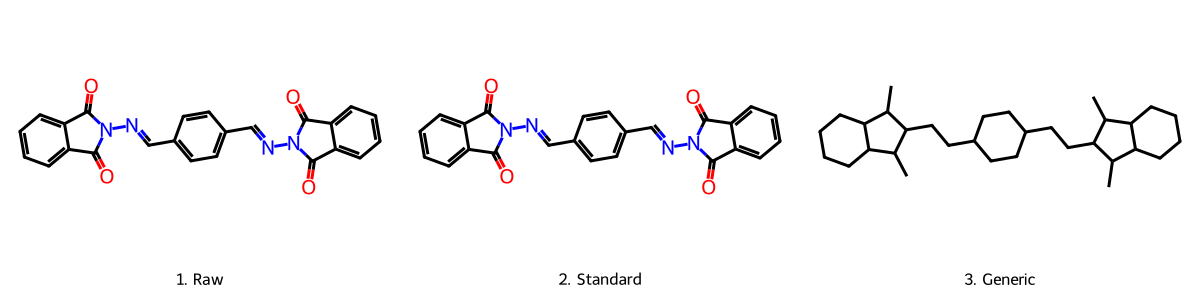

In [ ]:
# 1. 指定你想要查看的 Index (例如第 10 筆資料)
target_index = 2000
row = processed_df.iloc[target_index]

# 2. 列印文字資訊方便對照
print(f"--- 正在檢視 Index: {target_index} ---")
print(f"原始分子 (SMILES): {row['SMILES']}")
print(f"標準骨架 (Standard): {row['Standard_Scaffold']}")
print(f"通用骨架 (Generic) : {row['Generic_Scaffold']}")
display_molecular_hierarchy(row['SMILES'], row['Standard_Scaffold'], row['Generic_Scaffold'])


## 確認資料集藥物特徵分布
AI模型訓練本質上是類似模仿，對於分布外的數值可能存在有參考資料不足的風險。

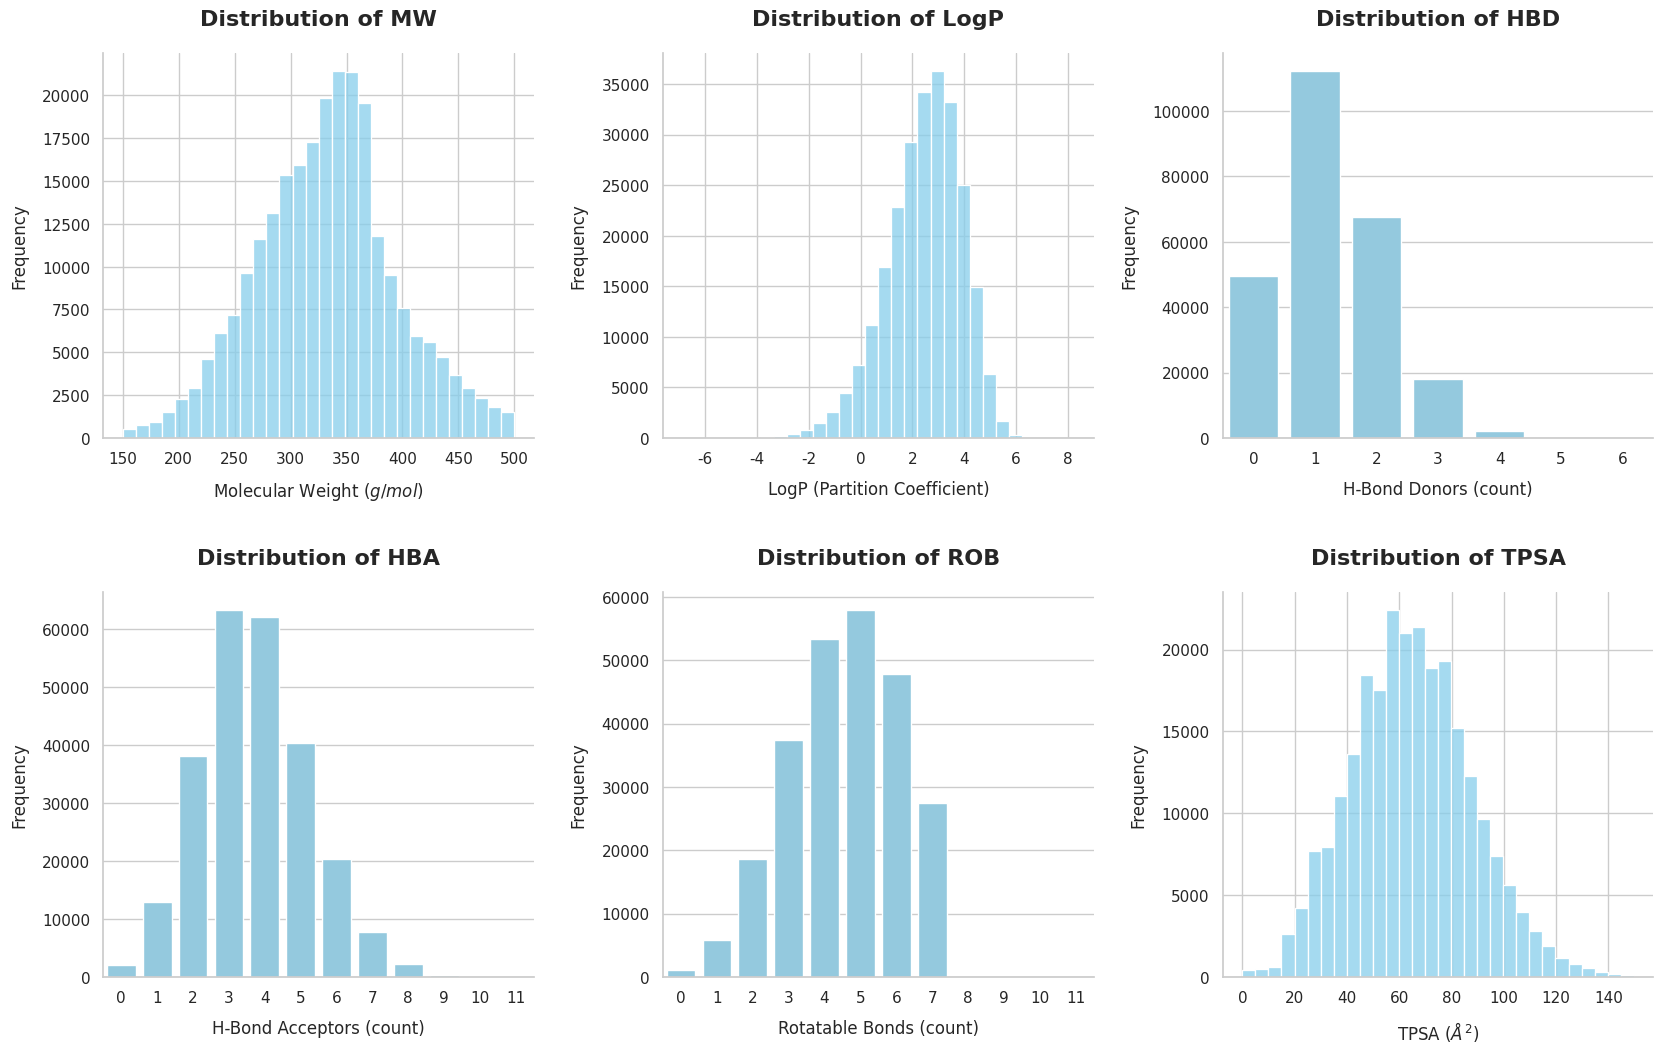

In [ ]:

# 1. 準備數據
plot_df = processed_df
sns.set_theme(style="whitegrid")

plot_config = {
    'MW': r'Molecular Weight ($g/mol$)',
    'LogP': 'LogP (Partition Coefficient)',
    'HBD': 'H-Bond Donors (count)',
    'HBA': 'H-Bond Acceptors (count)',
    'ROB': 'Rotatable Bonds (count)',
    'TPSA': r'TPSA ($\AA^2$)'
}

cols_to_plot = list(plot_config.keys())
discrete_cols = ['HBD', 'HBA', 'ROB']

# 2. 建立畫布
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()
plt.subplots_adjust(wspace=0.3, hspace=0.4)

for i, col in enumerate(cols_to_plot):
    if col in discrete_cols:
        # --- 離散數值 (Countplot) ---
        sns.countplot(data=plot_df, x=col, ax=axes[i], color='skyblue')

        # 標籤抽樣顯示（避免 ROB 或 HBA 太多數字擠在一起）
        n_ticks = len(axes[i].get_xticklabels())
        if n_ticks > 15:
            for n, label in enumerate(axes[i].get_xticklabels()):
                if n % 2 != 0: label.set_visible(False)
    else:
        # --- 連續數值 (Histplot) ---
        sns.histplot(plot_df[col], kde=False, ax=axes[i], color='skyblue', bins=30)

    # --- 統一 X 軸格式：全部強制為整數 ---
    axes[i].xaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))

    # 3. 美化標題與標籤
    axes[i].set_title(f'Distribution of {col}', fontsize=16, fontweight='bold', pad=20)
    axes[i].set_xlabel(plot_config[col], fontsize=12, labelpad=10)
    axes[i].set_ylabel('Frequency', fontsize=12, labelpad=10)

    sns.despine(ax=axes[i])

plt.show()

# Lipinski's Rule of Five (Ro5)
這是由輝瑞（Pfizer）科學家 Christopher Lipinski 在 1997 年提出的經驗法則，用來預測一個小分子是否具有良好的口服生物利用度（也就是吃下去後能不能順利被腸道吸收並進入血液）。這裡的「Five」指的是各條規則的判別值均為5或5的整數倍。


| 性質 | Ro5 | 現代藥物學觀點 | 說明 |
| :--- | :--- | :--- | :--- |
| 分子量 **MW** | $\le$ 500 | $\le$ 500 | 決定分子大小；過大會降低腸道滲透性。 |
| 油水分配係數 **LogP** | $\le$ 5 | -0.4 ~ 5.0 |  衡量脂溶性；過高易導致溶解度差或毒性。 |
| 氫鍵供體數 **HBD** | $\le$ 5 | $\le$ 5 | 分子表面可提供氫鍵上的氫原子的數量。 |
| 氫鍵受體數 **HBA** | $\le$ 10 | $\le$ 10 | 分子表面可接受氫鍵上的氫原子的數量。 |
| 可旋轉鍵數 **ROB** | 無提及 | $\le$ 10 | 影響分子的柔韌性與口服生物利用度。 |
| 拓撲極性表面積 **TPSA** | 無提及 | $\le$ 140 | 影響細胞滲透力；穿過血腦屏障 (BBB) 建議 < 90。 |